# Multiobjetivo: frente de Pareto y NSGA-II

Este notebook es aparte de `TT.ipynb`. A diferencia de los otros, usa el **recinto de prueba del proyecto** (100 × 60 m, 4 salidas, 9 módulos, 2000 personas) y su evaluador (`experimentos/potencial.py`). Hay dos razones:
- De ese recinto ya hay **1,776 layouts al azar evaluados** (`datos/correlacion_f1_f2.csv`) para dibujar la nube.
- Su evaluador es rápido (~0.2 s por layout), así que se puede correr un NSGA-II chico aquí mismo.

Los dos objetivos se **minimizan**: $f_1$, la distancia media a los servicios (`p-mediana.ipynb`), y $t_{95}$, el tiempo en que sale el 95 % de la gente (`evacuacion.ipynb`).

In [1]:
import os, sys, csv, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap

TT = os.path.dirname(os.getcwd()) if os.path.isdir(os.path.join("..", "nucleo")) else r"C:\Users\luisd\Desktop\TT"
sys.path.insert(0, TT + r"\nucleo")
sys.path.insert(0, TT + r"\experimentos")
import parametros as P
import muestreo as MU                 # población inicial por rechazo
import potencial as PO                # evaluar(rec, layout, aforo) -> f1, t95, violación...
from recinto import recinto_ejemplo, Colocacion

rec = recinto_ejemplo(h=P.H_CELDA)
AFORO = 2000

filas = [r for r in csv.DictReader(open(TT + r"\datos\correlacion_f1_f2.csv", encoding="utf-8")) if r["f1"]]
nube = np.array([[float(r["f1"]), float(r["t95"])] for r in filas])
v_nube = np.array([float(r["violacion"]) for r in filas])
valido = v_nube <= 0
print("%d layouts al azar, %d válidos" % (len(nube), valido.sum()))

1776 layouts al azar, 1206 válidos


## 1. Dominancia

$A$ **domina** a $B$ si $A$ no es peor que $B$ en ningún objetivo y es mejor en al menos uno. El **frente de Pareto** son los layouts a los que nadie domina: para mejorar uno de sus objetivos hay que empeorar el otro.

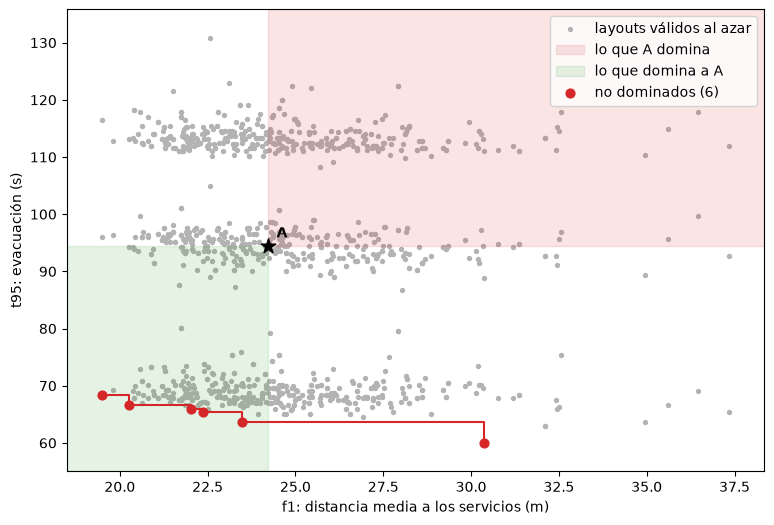

A domina a 302 layouts y lo dominan 281


In [2]:
def domina_pareto(a, b):
    return bool(np.all(a <= b) and np.any(a < b))

def no_dominados(F):
    """Índices de los puntos a los que nadie domina (2 objetivos: ordenar por f1 y barrer)."""
    orden = np.lexsort((F[:, 1], F[:, 0]))
    frente, mejor_t = [], np.inf
    for i in orden:
        if F[i, 1] < mejor_t:
            frente.append(i)
            mejor_t = F[i, 1]
    return np.array(frente)

V = nube[valido]
fr = no_dominados(V)
a = V[np.argsort(np.abs(V[:, 0] - np.median(V[:, 0])) + np.abs(V[:, 1] - np.median(V[:, 1])))[0]]   # uno de en medio

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(V[:, 0], V[:, 1], s=8, color="0.7", label="layouts válidos al azar")
ax.fill_between([a[0], V[:, 0].max() + 1], a[1], V[:, 1].max() + 5, color="C3", alpha=0.12, label="lo que A domina")
ax.fill_between([V[:, 0].min() - 1, a[0]], V[:, 1].min() - 5, a[1], color="C2", alpha=0.12, label="lo que domina a A")
o = fr[np.argsort(V[fr, 0])]
ax.step(V[o, 0], V[o, 1], where="post", color="C3", lw=1.5)
ax.scatter(V[fr, 0], V[fr, 1], s=40, color="C3", zorder=3, label="no dominados (%d)" % len(fr))
ax.scatter(*a, s=120, marker="*", color="k", zorder=4)
ax.annotate("A", a, xytext=(6, 6), textcoords="offset points", weight="bold")
ax.set_xlim(V[:, 0].min() - 1, V[:, 0].max() + 1); ax.set_ylim(V[:, 1].min() - 5, V[:, 1].max() + 5)
ax.set_xlabel("f1: distancia media a los servicios (m)"); ax.set_ylabel("t95: evacuación (s)"); ax.legend()
plt.show()
print("A domina a %d layouts y lo dominan %d" % (sum(domina_pareto(a, b) for b in V), sum(domina_pareto(b, a) for b in V)))

## 2. ¿Por qué no sumar los dos objetivos con pesos?

La **suma ponderada** $w\,f_1 + (1-w)\,t_{95}$ (con los objetivos normalizados) da un solo layout por cada peso. El **ε-restricción** fija un tope para $t_{95}$ y minimiza $f_1$. Barriendo los pesos y los topes sobre esta misma muestra:

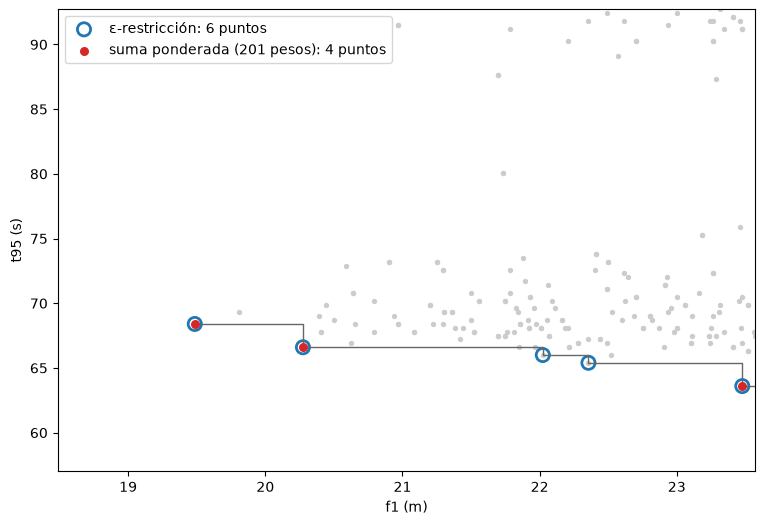

frente: 6 puntos | la suma ponderada encuentra 4 | el ε-restricción encuentra 6


In [3]:
Vn = (V - V.min(axis=0)) / (V.max(axis=0) - V.min(axis=0))      # cada objetivo de 0 a 1
por_pesos = {int(np.argmin(w * Vn[:, 0] + (1 - w) * Vn[:, 1])) for w in np.linspace(0, 1, 201)}
por_eps = {int(np.flatnonzero(V[:, 1] <= eps)[np.argmin(V[V[:, 1] <= eps, 0])]) for eps in V[fr, 1]}

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(V[:, 0], V[:, 1], s=8, color="0.8")
ax.step(V[o, 0], V[o, 1], where="post", color="0.4", lw=1)
ax.scatter(V[list(por_eps), 0], V[list(por_eps), 1], s=90, facecolors="none", edgecolors="C0", lw=2,
           label="ε-restricción: %d puntos" % len(por_eps))
ax.scatter(V[list(por_pesos), 0], V[list(por_pesos), 1], s=30, color="C3", zorder=3,
           label="suma ponderada (201 pesos): %d puntos" % len(por_pesos))
ax.set_xlim(V[fr, 0].min() - 1, np.percentile(V[:, 0], 40)); ax.set_ylim(V[fr, 1].min() - 3, np.percentile(V[:, 1], 40))
ax.set_xlabel("f1 (m)"); ax.set_ylabel("t95 (s)"); ax.legend()
plt.show()
print("frente: %d puntos | la suma ponderada encuentra %d | el ε-restricción encuentra %d"
      % (len(fr), len(por_pesos), len(por_eps)))

**Qué ver:** de los puntos del frente de esta muestra, la suma ponderada con 201 pesos distintos no los encuentra todos: los que quedan "hacia adentro" no los alcanza ningún peso. El ε-restricción sí los encuentra todos, pero hay que correr una optimización por cada tope. NSGA-II saca el frente completo en una sola corrida, sin elegir pesos ni topes.

## 3. Las piezas de NSGA-II

1. **Dominancia restringida** (Deb, 2000): un válido le gana a cualquier inválido; entre inválidos gana el que viola menos; entre válidos, Pareto. Así no hay que inventar un peso que mezcle metros de violación con segundos.
2. **Ordenamiento no dominado:** el frente 1 son los que nadie domina; se quitan, y los que quedan sin dominar son el frente 2, etc.
3. **Distancia de apiñamiento:** dentro de un frente se prefieren los puntos con vecinos lejanos, para que el frente no se amontone en un solo lugar.

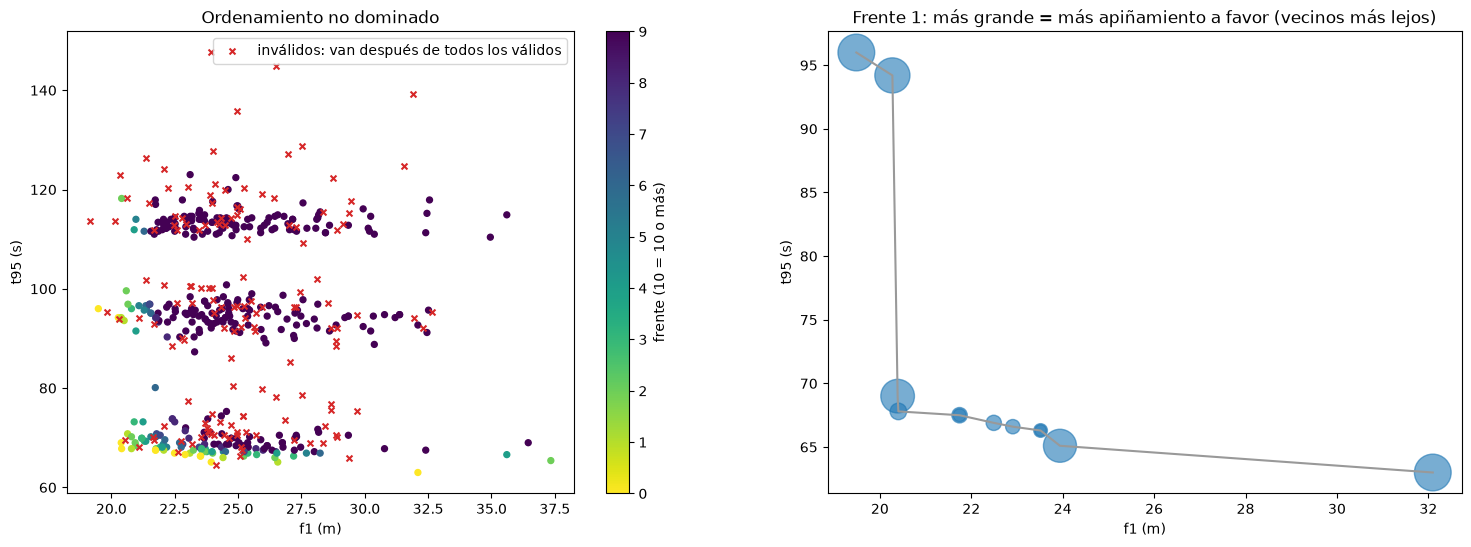

357 válidos y 143 inválidos -> 127 frentes; el primer inválido cae en el frente 37 (después de los 36 válidos)


In [4]:
def domina(fa, va, fb, vb):
    """Dominancia restringida (Deb 2000)."""
    if (va > 0) != (vb > 0):
        return vb > 0                     # 1. válido gana a inválido
    if va > 0:
        return va < vb                    # 2. entre inválidos, el que viola menos
    return domina_pareto(fa, fb)          # 3. entre válidos, Pareto

def ordenar_frentes(F, viol):
    """Ordenamiento no dominado rápido (Deb et al. 2002). Lista de frentes, cada uno con sus índices."""
    n = len(F)
    le_gana_a = [[] for _ in range(n)]
    le_ganan = np.zeros(n, dtype=int)
    for i in range(n):
        for j in range(i + 1, n):
            if domina(F[i], viol[i], F[j], viol[j]):
                le_gana_a[i].append(j); le_ganan[j] += 1
            elif domina(F[j], viol[j], F[i], viol[i]):
                le_gana_a[j].append(i); le_ganan[i] += 1
    frentes = [[i for i in range(n) if le_ganan[i] == 0]]
    while frentes[-1]:
        sig = []
        for i in frentes[-1]:
            for j in le_gana_a[i]:
                le_ganan[j] -= 1
                if le_ganan[j] == 0:
                    sig.append(j)
        frentes.append(sig)
    return frentes[:-1]

def apinamiento(F, frente):
    """Distancia de apiñamiento de cada punto del frente (los extremos: infinito)."""
    d = np.zeros(len(frente))
    if len(frente) <= 2:
        return np.full(len(frente), np.inf)
    sub = F[frente]
    for m in range(sub.shape[1]):
        o = np.argsort(sub[:, m])
        d[o[0]] = d[o[-1]] = np.inf
        rango = sub[o[-1], m] - sub[o[0], m]
        for k in range(1, len(o) - 1):
            d[o[k]] += (sub[o[k + 1], m] - sub[o[k - 1], m]) / max(rango, 1e-12)
    return d

muestra = np.random.default_rng(0).choice(len(nube), 500, replace=False)    # 500 de la nube, para que sea rápido
F, viol = nube[muestra], v_nube[muestra]
frentes = ordenar_frentes(F, viol)
rango = np.empty(len(F), dtype=int)
for r_, f in enumerate(frentes):
    rango[f] = r_

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
ok = viol <= 0
sc = ax[0].scatter(F[ok, 0], F[ok, 1], c=np.minimum(rango[ok], 9), cmap="viridis_r", s=18)
ax[0].scatter(F[~ok, 0], F[~ok, 1], marker="x", color="C3", s=18, label="inválidos: van después de todos los válidos")
fig.colorbar(sc, ax=ax[0], label="frente (10 = 10 o más)")
ax[0].set_xlabel("f1 (m)"); ax[0].set_ylabel("t95 (s)"); ax[0].legend(); ax[0].set_title("Ordenamiento no dominado")
f0 = np.array(frentes[0]); d = apinamiento(F, list(f0)); o0 = np.argsort(F[f0, 0])
ax[1].plot(F[f0[o0], 0], F[f0[o0], 1], color="0.6")
ax[1].scatter(F[f0, 0], F[f0, 1], s=np.where(np.isfinite(d), 40 + 600 * d / d[np.isfinite(d)].max(), 700),
              color="C0", alpha=0.6)
ax[1].set_xlabel("f1 (m)"); ax[1].set_ylabel("t95 (s)")
ax[1].set_title("Frente 1: más grande = más apiñamiento a favor (vecinos más lejos)")
plt.show()
print("%d válidos y %d inválidos -> %d frentes; el primer inválido cae en el frente %d (después de los %d válidos)"
      % (ok.sum(), (~ok).sum(), len(frentes), rango[~ok].min() + 1, rango[ok].max() + 1))

## 4. Cruce y mutación

- **Cruce por módulo:** cada módulo del hijo se hereda **entero** (x, y, rotación) de uno de los dos padres. Promediar coordenadas de dos layouts distintos da un hijo que no se parece a ninguno y casi siempre con módulos encimados.
- **Ojo, se empareja por tipo:** el sanitario 1 del hijo sale del sanitario 1 de A o del de B. Si se emparejan por posición en la lista, y cada layout tiene los tipos en otro orden, el hijo puede salir con 4 comidas y 1 sanitario. Eso le pasaba al cruce de `experimentos/frente.py` hasta el 13 de octubre de 2026; ya está corregido.
- **Mutación:** mover uno o dos módulos un poco (σ que se achica con las generaciones), girarlos, o de vez en cuando un salto largo.
- **Un hijo inválido no se tira:** compite con la dominancia restringida. Dos padres válidos pueden dar un hijo inválido, y uno inválido puede dar uno válido.

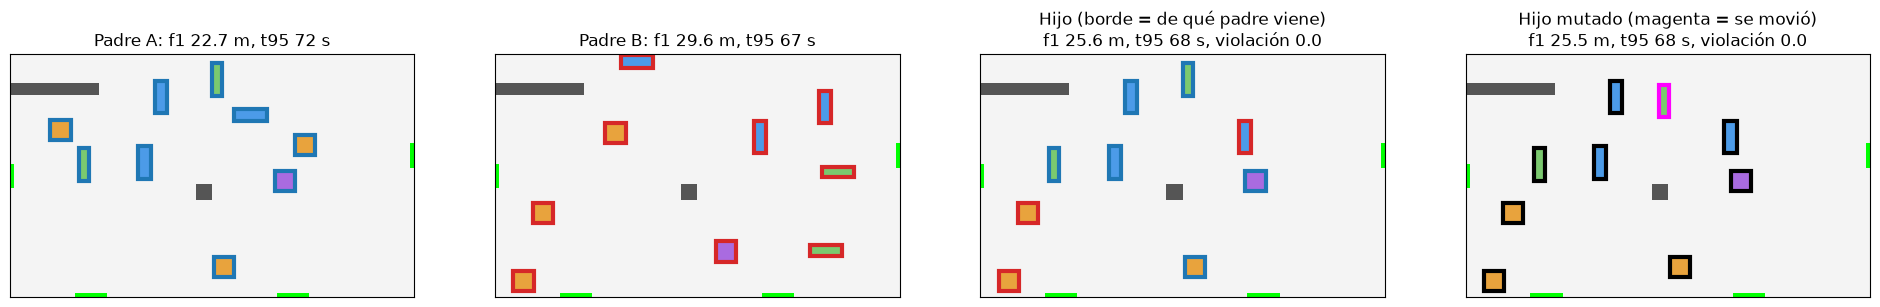

In [5]:
COLOR = {"SAN": "#4C9BE8", "COM": "#E8A33D", "BEB": "#7BC96F", "MED": "#A96BE0"}

def dibujar(ax, lay, titulo, borde=None):
    """El recinto de prueba con un layout. 'borde': color del contorno de cada módulo."""
    ext = (0, rec.W, 0, rec.H)
    ax.imshow(np.where(rec.muros, 1.0, np.nan), origin="lower", extent=ext, cmap=ListedColormap(["#555555"]))
    ax.imshow(np.where(rec.mascara_salidas(), 1.0, np.nan), origin="lower", extent=ext, cmap=ListedColormap(["lime"]))
    for k, c in enumerate(lay):
        x, y, w, f = c.rect()
        ax.add_patch(Rectangle((x, y), w, f, facecolor=COLOR[c.tipo], edgecolor=(borde or {}).get(k, "black"),
                               lw=3 if borde else 0.8))
    ax.set_xlim(0, rec.W); ax.set_ylim(0, rec.H); ax.set_aspect("equal"); ax.set_facecolor("#f4f4f4")
    ax.set_title(titulo); ax.set_xticks([]); ax.set_yticks([])

def por_tipo(lay):
    """El mismo layout con los módulos ordenados por tipo: así el i-ésimo de dos layouts es del mismo tipo."""
    return sorted(lay, key=lambda c: c.tipo)

def cruzar(a, b, rng):
    a, b = por_tipo(a), por_tipo(b)
    m = rng.random(len(a)) < 0.5
    return [Colocacion(c.tipo, c.x, c.y, c.rot) for c in (a[i] if m[i] else b[i] for i in range(len(a)))], m

rng = np.random.default_rng(3)
padres = [por_tipo(l) for _, l in MU.muestra(rec, 2, semilla=21, modo="estricto")[0]]
hijo, de_a = cruzar(padres[0], padres[1], rng)
mutado = PO.muta(hijo, rec, rng, sigma=8.0)
ev = {n: PO.evaluar(rec, l, AFORO) for n, l in (("A", padres[0]), ("B", padres[1]), ("hijo", hijo), ("mutado", mutado))}

fig, ax = plt.subplots(1, 4, figsize=(24, 4.2))
dibujar(ax[0], padres[0], "Padre A: f1 %.1f m, t95 %.0f s" % (ev["A"]["f1"], ev["A"]["t95"]), {k: "C0" for k in range(9)})
dibujar(ax[1], padres[1], "Padre B: f1 %.1f m, t95 %.0f s" % (ev["B"]["f1"], ev["B"]["t95"]), {k: "C3" for k in range(9)})
dibujar(ax[2], hijo, "Hijo (borde = de qué padre viene)\nf1 %.1f m, t95 %.0f s, violación %.1f"
        % (ev["hijo"]["f1"], ev["hijo"]["t95"], ev["hijo"]["viol"]), {k: "C0" if de_a[k] else "C3" for k in range(9)})
cambio = {k: "black" if (h.x, h.y, h.rot) == (m.x, m.y, m.rot) else "magenta" for k, (h, m) in enumerate(zip(hijo, mutado))}
dibujar(ax[3], mutado, "Hijo mutado (magenta = se movió)\nf1 %.1f m, t95 %.0f s, violación %.1f"
        % (ev["mutado"]["f1"], ev["mutado"]["t95"], ev["mutado"]["viol"]), cambio)
plt.show()

## 5. Una corrida chica de NSGA-II

24 layouts × 15 generaciones = 384 evaluaciones (~1.5 min). Cada generación:
1. **Torneo binario** para elegir padres: gana el de mejor frente; si empatan, el de más apiñamiento.
2. **Cruce** (90 %) y **mutación** → 24 hijos.
3. Padres e hijos compiten **juntos** ($\mu + \lambda$): se llenan los 24 lugares frente por frente, y el último frente que no cabe completo se recorta por apiñamiento.

La población inicial son 24 layouts **válidos** sacados por rechazo; de ahí en adelante nadie se tira por inválido.

In [6]:
def evalua(lays):
    ms = [PO.evaluar(rec, l, AFORO) for l in lays]
    return np.array([[m["f1"], m["t95"]] for m in ms]), np.array([m["viol"] for m in ms])

def nsga2(pob=24, gens=15, sigma0=10.0, semilla=11):
    rng = np.random.default_rng(semilla)
    P_ = [l for _, l in MU.muestra(rec, pob, semilla=semilla, modo="estricto")[0]]
    F, V_ = evalua(P_)
    historia = [F.copy()]
    for g in range(gens):
        sigma = sigma0 * (1 - 0.8 * g / max(1, gens - 1))          # pasos grandes al principio, finos al final
        frentes = ordenar_frentes(F, V_)
        rango, dist = np.empty(len(P_), int), np.empty(len(P_))
        for r_, f in enumerate(frentes):
            rango[f] = r_
            dist[f] = apinamiento(F, f)

        def torneo():
            i, j = rng.integers(len(P_), size=2)
            if rango[i] != rango[j]:
                return P_[i] if rango[i] < rango[j] else P_[j]
            return P_[i] if dist[i] > dist[j] else P_[j]

        hijos = []
        for _ in range(pob):
            h = cruzar(torneo(), torneo(), rng)[0] if rng.random() < 0.9 else torneo()
            hijos.append(PO.muta(h, rec, rng, sigma))
        Fh, Vh = evalua(hijos)

        P_, F, V_ = P_ + hijos, np.vstack([F, Fh]), np.concatenate([V_, Vh])      # padres + hijos
        nuevos = []
        for f in ordenar_frentes(F, V_):
            if len(nuevos) + len(f) <= pob:
                nuevos += f
            else:
                d = apinamiento(F, f)
                nuevos += [f[i] for i in np.argsort(-d)[:pob - len(nuevos)]]
                break
        P_, F, V_ = [P_[i] for i in nuevos], F[nuevos], V_[nuevos]
        historia.append(F.copy())
        print("gen %2d: %2d en el frente | mejor f1 %.1f m | mejor t95 %.1f s | inválidos en la población: %d"
              % (g + 1, len(ordenar_frentes(F, V_)[0]), F[V_ <= 0, 0].min(), F[V_ <= 0, 1].min(), (V_ > 0).sum()))
    return P_, F, V_, historia

t0 = time.time()
pob_final, F_final, V_final, historia = nsga2()
print("%.0f s" % (time.time() - t0))
from collections import Counter
print("composición de la población final:", {tuple(sorted(Counter(c.tipo for c in l).items())) for l in pob_final})

gen  1:  2 en el frente | mejor f1 20.6 m | mejor t95 66.3 s | inválidos en la población: 0


gen  2:  4 en el frente | mejor f1 20.5 m | mejor t95 64.8 s | inválidos en la población: 0


gen  3:  4 en el frente | mejor f1 20.4 m | mejor t95 64.8 s | inválidos en la población: 0


gen  4:  6 en el frente | mejor f1 20.4 m | mejor t95 64.8 s | inválidos en la población: 0


gen  5:  6 en el frente | mejor f1 20.4 m | mejor t95 64.8 s | inválidos en la población: 0


...

gen 11:  5 en el frente | mejor f1 19.9 m | mejor t95 63.0 s | inválidos en la población: 0


gen 12:  7 en el frente | mejor f1 19.9 m | mejor t95 62.4 s | inválidos en la población: 0


gen 13:  5 en el frente | mejor f1 19.4 m | mejor t95 62.4 s | inválidos en la población: 0


gen 14:  5 en el frente | mejor f1 19.0 m | mejor t95 62.4 s | inválidos en la población: 0


gen 15:  6 en el frente | mejor f1 19.0 m | mejor t95 62.1 s | inválidos en la población: 0
81 s
composición de la población final: {(('BEB', 2), ('COM', 3), ('MED', 1), ('SAN', 3))}


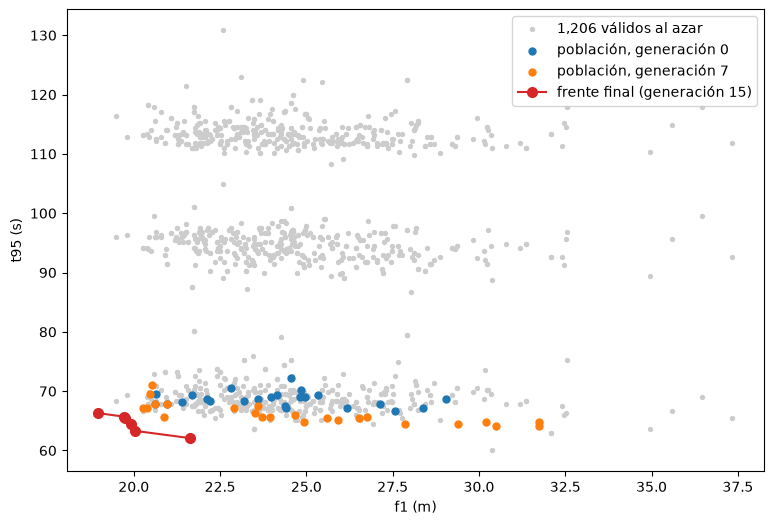

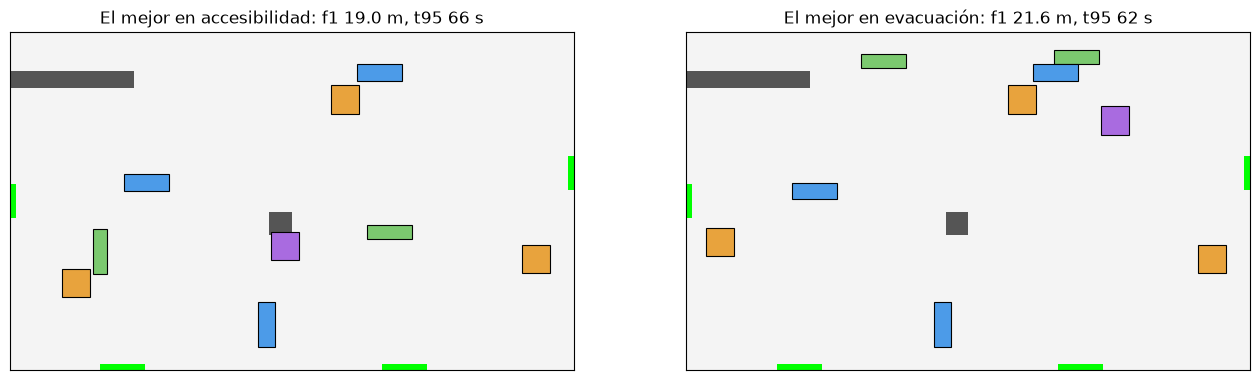

mediana al azar: f1 24.3 m, t95 94.5 s


In [7]:
f_ok = [i for i in ordenar_frentes(F_final, V_final)[0] if V_final[i] <= 0]
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(V[:, 0], V[:, 1], s=8, color="0.8", label="1,206 válidos al azar")
for g, color in ((0, "C0"), (7, "C1")):
    ax.scatter(historia[g][:, 0], historia[g][:, 1], s=25, color=color, label="población, generación %d" % g)
o = sorted(f_ok, key=lambda i: F_final[i, 0])
ax.plot(F_final[o, 0], F_final[o, 1], "o-", color="C3", ms=7, label="frente final (generación 15)")
ax.set_xlabel("f1 (m)"); ax.set_ylabel("t95 (s)"); ax.legend()
plt.show()

i1, i2 = min(f_ok, key=lambda i: F_final[i, 0]), min(f_ok, key=lambda i: F_final[i, 1])
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
dibujar(ax[0], pob_final[i1], "El mejor en accesibilidad: f1 %.1f m, t95 %.0f s" % tuple(F_final[i1]))
dibujar(ax[1], pob_final[i2], "El mejor en evacuación: f1 %.1f m, t95 %.0f s" % tuple(F_final[i2]))
plt.show()
print("mediana al azar: f1 %.1f m, t95 %.1f s" % tuple(np.median(V, axis=0)))

**Qué ver:**
- En 15 generaciones la población baja hacia la orilla inferior izquierda de la nube. El frente final va de $f_1$ = 19.0 m con $t_{95}$ = 66 s a $f_1$ = 21.6 m con $t_{95}$ = 62 s: para ganar 4 s de evacuación hay que caminar 2.6 m más en promedio. Eso es un compromiso real entre los dos objetivos.
- Los extremos son layouts distintos. El de mejor $f_1$ reparte cada tipo por todo el recinto, cerca de donde está la gente; el de mejor $t_{95}$ manda la mayoría de los módulos hacia la pared norte, lejos de las salidas y de los caminos hacia ellas.
- Con 384 evaluaciones el frente apenas llega a la orilla de la nube (lo mejor al azar: $f_1$ = 19.5 m, $t_{95}$ = 60 s). El experimento del proyecto usa 48 × 50 = 2,448.

**Lo que pasaba con `experimentos/frente.py`** (corregido el 13 de octubre de 2026): su cruce emparejaba los módulos por posición, no por tipo. En esta misma corrida, con ese cruce, el "mejor" llegaba a $f_1$ = 12.4 m, pero con 8 sanitarios y 1 comida: sin bebidas ni primeros auxilios, esos tipos ni siquiera entran en $f_1$. Por eso los números de NSGA-II de `experimentos/OPTIMIZADOR.md` ($f_1$ = 8.35 m, −65 %) hay que volver a correrlos ahora que el cruce está corregido. Lo publicado en el sitio no sale de ahí: sus 18 layouts tienen 3 sanitarios, 3 comidas, 2 bebidas y 1 de primeros auxilios.

## Referencias

- Deb, K., Pratap, A., Agarwal, S. y Meyarivan, T. (2002). A fast and elitist multiobjective genetic algorithm: NSGA-II. *IEEE Transactions on Evolutionary Computation*, 6(2), 182–197.
- Deb, K. (2000). An efficient constraint handling method for genetic algorithms. *Computer Methods in Applied Mechanics and Engineering*, 186(2–4), 311–338.